# Electrochemistry: from the Nernst equation to cyclic voltammetry

This notebook works through five topics with `echem`:

1. galvanic cells from a table of standard potentials,
2. a Nernst concentration cell,
3. Butler-Volmer kinetics and a Tafel analysis of synthetic data,
4. a Koutecky-Levich analysis of rotating-disk data,
5. cyclic voltammetry simulated by finite differences, compared with Randles-Sevcik, plus the effect of slow electron transfer.

The data in sections 3–4 are **synthetic**: they are generated from known parameters plus noise to show how each analysis recovers them.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import echem as ec

rng = np.random.default_rng(11)

## 1. Galvanic cells

In [2]:
pairs = [("Cu2+/Cu", "Zn2+/Zn"), ("Ag+/Ag", "Cu2+/Cu"), ("Cl2/Cl-", "H+/H2"), ("O2/H2O", "H+/H2")]
print(f"{'cathode':<10}{'anode':<10}{'E0 (V)':>8}{'dG (kJ/mol)':>14}{'log10 K':>10}")
for cat, an in pairs:
    E = ec.cell_potential(cat, an)
    n = ec.STANDARD_POTENTIALS[cat][1] * ec.STANDARD_POTENTIALS[an][1] // np.gcd(ec.STANDARD_POTENTIALS[cat][1], ec.STANDARD_POTENTIALS[an][1])
    print(f"{cat:<10}{an:<10}{E:>8.2f}{ec.delta_g(n, E)/1000:>14.1f}{np.log10(ec.equilibrium_constant(n, E)):>10.1f}")

cathode   anode       E0 (V)   dG (kJ/mol)   log10 K
Cu2+/Cu   Zn2+/Zn       1.10        -212.3      37.2
Ag+/Ag    Cu2+/Cu       0.46         -88.8      15.6
Cl2/Cl-   H+/H2         1.36        -262.4      46.0
O2/H2O    H+/H2         1.23        -474.7      83.2


## 2. Concentration cell: 59 mV per decade

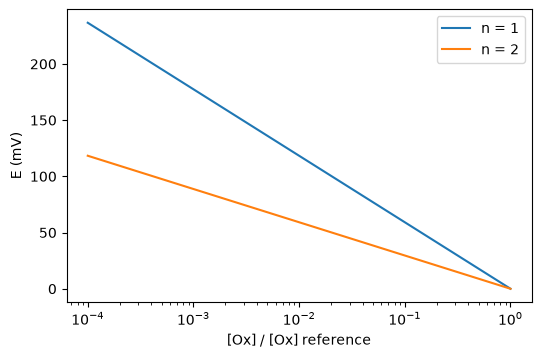

In [3]:
ratio = np.logspace(-4, 0, 50)
plt.figure(figsize=(6, 3.8))
for n in (1, 2):
    plt.semilogx(ratio, 1000 * (ec.nernst(0.0, n, 1.0) - ec.nernst(0.0, n, 1 / ratio)), label=f"n = {n}")
plt.xlabel("[Ox] / [Ox] reference"); plt.ylabel("E (mV)"); plt.legend(); plt.show()

## 3. Butler-Volmer and Tafel analysis

Synthetic polarisation data with $i_0$ = 0.2 mA/cm², α = 0.4 and 2 % multiplicative noise.

anodic branch:   alpha_a = 0.401 (true 0.4), i0 = 1.99 A/m^2 (true 2.0), slope 148 mV/dec
cathodic branch: alpha_c = 0.602 (true 0.6), i0 = 1.96 A/m^2


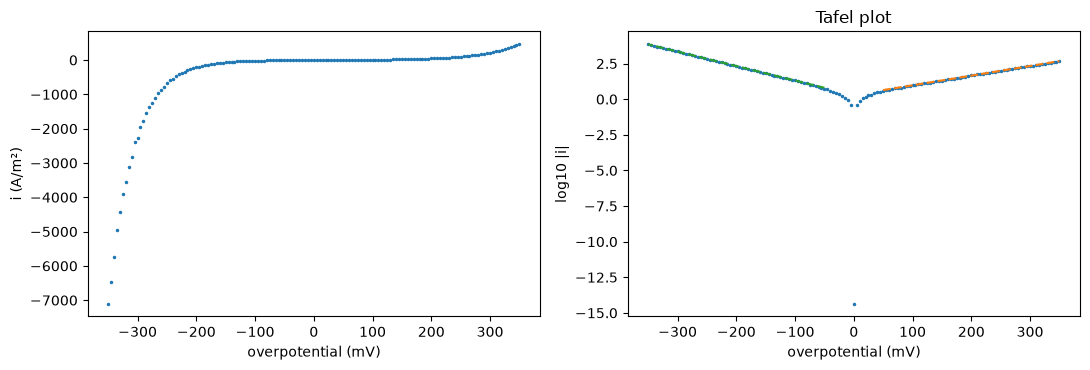

In [4]:
eta = np.linspace(-0.35, 0.35, 141)
i_true = ec.butler_volmer(eta, 2.0, alpha_a=0.4)  # A/m^2  (0.2 mA/cm^2)
i_obs = i_true * (1 + 0.02 * rng.standard_normal(eta.size))
fa = ec.fit_tafel(eta, i_obs, "anodic", min_eta=0.12)
fc = ec.fit_tafel(eta, i_obs, "cathodic", min_eta=0.12)
print(f"anodic branch:   alpha_a = {fa['alpha']:.3f} (true 0.4), i0 = {fa['i0']:.2f} A/m^2 (true 2.0), slope {1000*fa['slope']:.0f} mV/dec")
print(f"cathodic branch: alpha_c = {fc['alpha']:.3f} (true 0.6), i0 = {fc['i0']:.2f} A/m^2")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(eta * 1000, i_obs, ".", ms=3); axes[0].set_xlabel("overpotential (mV)"); axes[0].set_ylabel("i (A/m²)")
axes[1].plot(eta * 1000, np.log10(np.abs(i_obs)), ".", ms=3, label="data")
for fit, sgn in ((fa, 1), (fc, -1)):
    e = np.linspace(0.05, 0.35, 10) * sgn
    axes[1].plot(e * 1000, np.log10(fit["i0"]) + np.abs(e) / fit["slope"], "--")
axes[1].set_xlabel("overpotential (mV)"); axes[1].set_ylabel("log10 |i|"); axes[1].set_title("Tafel plot")
plt.tight_layout(); plt.show()

## 4. Rotating disk: Koutecky-Levich

kinetic current from intercept: 149.9 uA (true 150.0 uA)


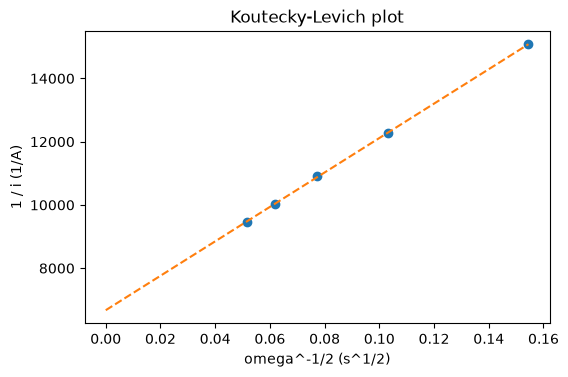

In [5]:
rpm = np.array([400, 900, 1600, 2500, 3600])
omega = 2 * np.pi * rpm / 60
iL = ec.levich_current(1, 0.196e-4, 7e-10, omega, 1e-6, 2.0)
i_k = 1.5e-4
i_meas = ec.koutecky_levich(i_k, iL) * (1 + 0.005 * rng.standard_normal(rpm.size))
m, c = np.polyfit(omega**-0.5, 1 / i_meas, 1)
print(f"kinetic current from intercept: {1/c*1e6:.1f} uA (true {i_k*1e6:.1f} uA)")
plt.figure(figsize=(6, 3.8))
plt.plot(omega**-0.5, 1 / i_meas, "o"); xx = np.linspace(0, omega.min()**-0.5, 20); plt.plot(xx, m * xx + c, "--")
plt.xlabel("omega^-1/2 (s^1/2)"); plt.ylabel("1 / i (1/A)"); plt.title("Koutecky-Levich plot"); plt.show()

## 5. Cyclic voltammetry

1 mM of a one-electron couple, D = 1×10⁻⁹ m²/s, on a 1 mm² electrode.

v = 0.025 V/s: |ipc| = 1.343 uA, Randles-Sevcik = 1.343 uA, dEp = 57.7 mV


v = 0.100 V/s: |ipc| = 2.686 uA, Randles-Sevcik = 2.686 uA, dEp = 57.7 mV


v = 0.400 V/s: |ipc| = 5.373 uA, Randles-Sevcik = 5.373 uA, dEp = 57.7 mV


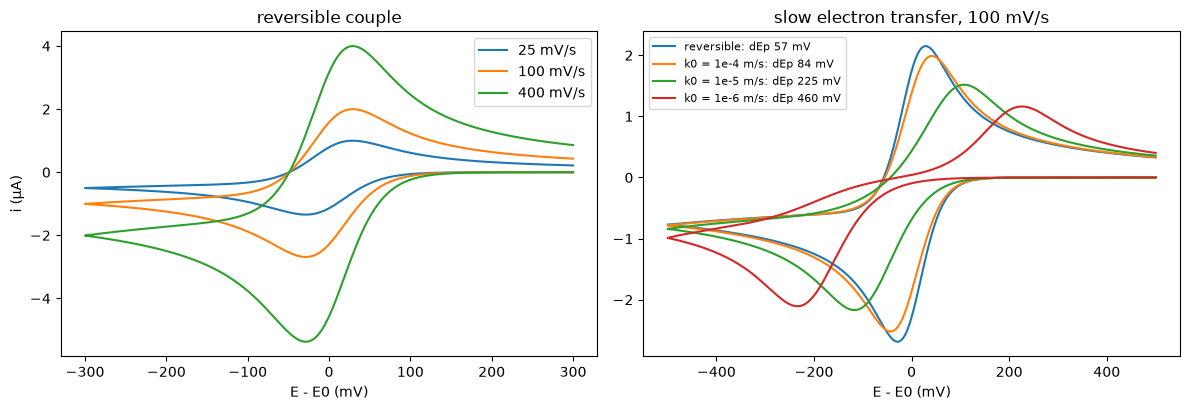

In [6]:
base = dict(E_start=0.3, E_switch=-0.3, E0=0.0, n=1, conc=1.0, D=1e-9, area=1e-6)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for v in (0.025, 0.1, 0.4):
    cv = ec.simulate_cv(scan_rate=v, **base)
    axes[0].plot(cv.E * 1000, cv.i * 1e6, label=f"{1000*v:.0f} mV/s")
    print(f"v = {v:5.3f} V/s: |ipc| = {abs(cv.cathodic_peak()[1])*1e6:.3f} uA, Randles-Sevcik = "
          f"{ec.randles_sevcik(1, 1e-6, 1.0, 1e-9, v)*1e6:.3f} uA, dEp = {cv.peak_separation()*1000:.1f} mV")
axes[0].set_xlabel("E - E0 (mV)"); axes[0].set_ylabel("i (µA)"); axes[0].legend(); axes[0].set_title("reversible couple")
for k0, lab in [(None, "reversible"), (1e-4, "k0 = 1e-4 m/s"), (1e-5, "k0 = 1e-5 m/s"), (1e-6, "k0 = 1e-6 m/s")]:
    cv = ec.simulate_cv(scan_rate=0.1, k0=k0, **{**base, "E_switch": -0.5, "E_start": 0.5})
    axes[1].plot(cv.E * 1000, cv.i * 1e6, label=f"{lab}: dEp {cv.peak_separation()*1000:.0f} mV")
axes[1].set_xlabel("E - E0 (mV)"); axes[1].legend(fontsize=8); axes[1].set_title("slow electron transfer, 100 mV/s")
plt.tight_layout(); plt.show()